# Lipid Molecular-Axis Projection Distributions

This notebook analyzes lipid molecular orientations in all-atom
MD simulations of Aβ40 and Aβ42 hexamers with free DMPC and
DMPC/cholesterol lipids, alongside lipid-only controls.

For each frame, the molecular axis of each lipid is projected
onto the collective nematic director obtained from the nematic
ordering tensor.

The analysis includes:
- Molecular-axis projections (u · n)
- Probability-density distributions
- Fractions of lipid orientations aligned within 45° of
  the nematic axis

The analysis covers 900–1000 ns of each trajectory.
Five independent replicas are analyzed for each Aβ system
and three for each lipid-only control.

In [1]:
import mdtraj as md
import numpy as np


def n_director(traj, indices="chains"):
    """
    Calculate the principal eigenvectors of the nematic ordering tensor.

    For each trajectory frame, molecular directors are calculated using
    MDTraj. These directors are used to construct the nematic ordering
    tensor (Q), which is diagonalized to obtain its eigenvectors.

    Parameters
    ----------
    traj : md.Trajectory
        Molecular dynamics trajectory.

    indices : str or array-like, default="chains"
        Molecular groups used to calculate individual directors.

    Returns
    -------
    largest_eigenvectors : np.ndarray
        Eigenvectors corresponding to the largest eigenvalue
        of the Q-tensor for each frame.

    middle_eigenvectors : np.ndarray
        Eigenvectors corresponding to the middle eigenvalue
        of the Q-tensor for each frame.

    smallest_eigenvectors : np.ndarray
        Eigenvectors corresponding to the smallest eigenvalue
        of the Q-tensor for each frame.
    """

    # Calculate molecular directors for each group in each frame.
    all_directors = md.compute_directors(traj, indices)

    # Construct the nematic ordering tensor for each frame.
    Q_ab = md.geometry.order._compute_Q_tensor(all_directors)

    # Initialize lists to store eigenvectors.
    largest_eigenvectors = []
    middle_eigenvectors = []
    smallest_eigenvectors = []

    # Diagonalize the Q-tensor and sort eigenvectors by eigenvalue.
    for i in range(Q_ab.shape[0]):
        eigenvalues, eigenvectors = np.linalg.eig(Q_ab[i])

        sorted_indices = np.argsort(eigenvalues)
        sorted_eigenvalues = eigenvalues[sorted_indices]
        sorted_eigenvectors = eigenvectors[:, sorted_indices]

        # Store eigenvectors corresponding to each eigenvalue.
        largest_eigenvectors.append(sorted_eigenvectors[:, -1])

        if sorted_eigenvectors.shape[1] > 2:
            middle_eigenvectors.append(sorted_eigenvectors[:, 1:-1].T)

        smallest_eigenvectors.append(sorted_eigenvectors[:, 0])

    # Convert lists to NumPy arrays.
    largest_eigenvectors = np.array(largest_eigenvectors)
    middle_eigenvectors = np.array(middle_eigenvectors)
    smallest_eigenvectors = np.array(smallest_eigenvectors)

    return largest_eigenvectors, middle_eigenvectors, smallest_eigenvectors

In [2]:

def projection_all_lipids(traj_files, top_files, lipid_names=("DMPC", "CHL1"), time_range_ps=None):
    """
    Calculate the distribution of lipid molecular-axis projections onto
    the collective nematic director.

    For each trajectory frame, the molecular axis (u) of each lipid is
    projected onto the collective nematic director (n):

        projection = u · n

    Projections from all selected lipids, frames, and trajectories are
    combined into a normalized probability-density histogram.

    Parameters
    ----------
    traj_files : list of str
        Paths to molecular dynamics trajectory files (.xtc).
    top_files : list of str
        Paths to corresponding topology files (.gro).
    lipid_names : tuple of str, optional
        Lipid residue names included in the analysis.
        Default is ("DMPC", "CHL1").
    time_range_ps : tuple of (float, float), optional
        Start and end times in picoseconds.
        If None, all trajectory frames are included.

    Returns
    -------
    x : np.ndarray
        Centers of the histogram bins.
    density : np.ndarray
        Normalized probability density of the projections.
    all_projections : np.ndarray
        Individual projection values from all selected trajectories.
    """

    all_projections = []

    for traj_file, top_file in zip(traj_files, top_files):

        # Load trajectory and topology.
        traj = md.load(traj_file, top=top_file)

        # Select the specified time interval (ps).
        if time_range_ps is not None:
            start, end = time_range_ps
            traj = traj.slice(np.where((traj.time >= start) & (traj.time <= end))[0])

        # Collect atom indices for all selected lipid molecules.
        molecule_indices = [
            [atom.index for atom in res.atoms]
            for res in traj.top.residues if res.name in lipid_names
        ]

        # Calculate individual lipid molecular axes.
        mol_axes = md.compute_directors(traj, indices=molecule_indices)

        # Calculate the collective nematic director for each frame.
        directors, _, _ = n_director(traj, indices=molecule_indices)

        # Project each lipid molecular axis onto the nematic director.
        for i in range(traj.n_frames):

            n = directors[i] / np.linalg.norm(directors[i])
            u = mol_axes[i]

            proj = np.dot(u, n)
            all_projections.append(proj)

    # Combine projections from all trajectories and frames.
    all_projections = np.concatenate(all_projections)

    # Calculate the normalized probability-density histogram.
    bins = np.linspace(-1, 1, 50)
    density, edges = np.histogram(all_projections, bins=bins, density=True)

    # Calculate histogram bin centers.
    x = 0.5 * (edges[:-1] + edges[1:])

    return x, density, all_projections


## Read data

In [3]:
from pathlib import Path

BASE_DIR = Path("/path/to/xtc_files")

def get_files(folder, n):
    path = BASE_DIR / folder

    xtc = [str(path / f"movie_smooth_{i:02d}.xtc") for i in range(1, n + 1)]
    gro = [str(path / f"movie_smooth_{i:02d}.gro") for i in range(1, n + 1)]

    return xtc, gro


# Aβ40 and Aβ42 with 30 DMPC
ab40_30dmpc_xtc, ab40_30dmpc_gro = get_files("AB40_six_monomers_30DMPC", 5)
ab42_30dmpc_xtc, ab42_30dmpc_gro = get_files("AB42_six_monomers_30DMPC", 5)

# Aβ40 and Aβ42 with 21 DMPC + 9 CHOL
ab40_21dmpc_9chol_xtc, ab40_21dmpc_9chol_gro = get_files("AB40_six_monomers_21DMPC_9CHL1", 5)
ab42_21dmpc_9chol_xtc, ab42_21dmpc_9chol_gro = get_files("AB42_six_monomers_21DMPC_9CHL1", 5)

# Lipid-only controls
control_30dmpc_xtc, control_30dmpc_gro = get_files("30DMPC_Control", 3)
control_21dmpc_9chol_xtc, control_21dmpc_9chol_gro = get_files("21DMPC_9CHL1_Control", 3)


## Analysis

In [4]:

# Analysis time interval: 900–1000 ns (in ps)
TIME_RANGE_PS = (900000, 1000000)

# Lipid-only controls
control_30dmpc_x, control_30dmpc_y, control_30dmpc_proj = projection_all_lipids(
    control_30dmpc_xtc, control_30dmpc_gro, time_range_ps=TIME_RANGE_PS
)

control_21dmpc_9chol_x, control_21dmpc_9chol_y, control_21dmpc_9chol_proj = projection_all_lipids(
    control_21dmpc_9chol_xtc, control_21dmpc_9chol_gro, time_range_ps=TIME_RANGE_PS
)

# Aβ40 and Aβ42 with 30 DMPC
ab40_30dmpc_x, ab40_30dmpc_y, ab40_30dmpc_proj = projection_all_lipids(
    ab40_30dmpc_xtc, ab40_30dmpc_gro, time_range_ps=TIME_RANGE_PS
)

ab42_30dmpc_x, ab42_30dmpc_y, ab42_30dmpc_proj = projection_all_lipids(
    ab42_30dmpc_xtc, ab42_30dmpc_gro, time_range_ps=TIME_RANGE_PS
)

# Aβ40 and Aβ42 with 21 DMPC + 9 CHOL
ab40_21dmpc_9chol_x, ab40_21dmpc_9chol_y, ab40_21dmpc_9chol_proj = projection_all_lipids(
    ab40_21dmpc_9chol_xtc, ab40_21dmpc_9chol_gro, time_range_ps=TIME_RANGE_PS
)

ab42_21dmpc_9chol_x, ab42_21dmpc_9chol_y, ab42_21dmpc_9chol_proj = projection_all_lipids(
    ab42_21dmpc_9chol_xtc, ab42_21dmpc_9chol_gro, time_range_ps=TIME_RANGE_PS
)


## Plot

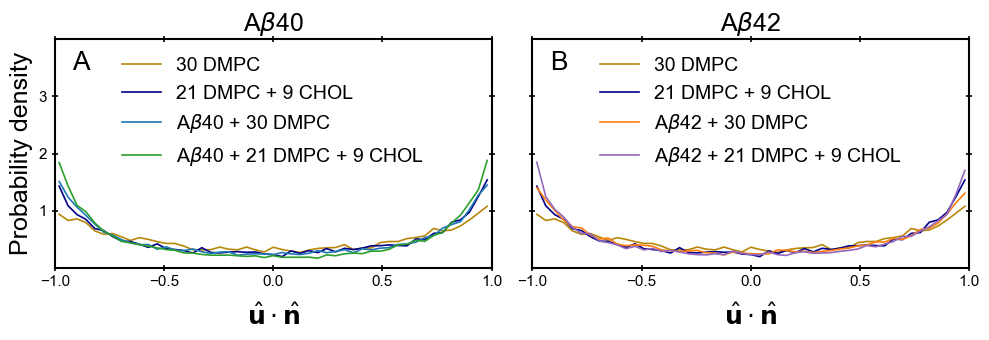

In [5]:
import matplotlib.pyplot as plt

# Colors for Aβ40, Aβ42, and lipid-only controls
colors_40 = ['#1f77b4', '#2ca02c']
colors_42 = ['#ff7f0e', '#9467bd']
control_colors = ['darkgoldenrod', 'darkblue']

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=100, sharey=True)

# Aβ40 panel
ax = axes[0]

ax.plot(control_30dmpc_x, control_30dmpc_y,
        lw=1.2, color=control_colors[0], label='30 DMPC')
ax.plot(control_21dmpc_9chol_x, control_21dmpc_9chol_y,
        lw=1.2, color=control_colors[1], label='21 DMPC + 9 CHOL')
ax.plot(ab40_30dmpc_x, ab40_30dmpc_y,
        lw=1.2, color=colors_40[0], label=r'A$\beta$40 + 30 DMPC')
ax.plot(ab40_21dmpc_9chol_x, ab40_21dmpc_9chol_y,
        lw=1.2, color=colors_40[1], label=r'A$\beta$40 + 21 DMPC + 9 CHOL')

ax.set_title(r'A$\beta$40', fontsize=18, pad=6)
ax.set_xlabel(r"$\hat{\mathbf{u}} \cdot \hat{\mathbf{n}}$", fontsize=18, labelpad=10)
ax.legend(fontsize=14, frameon=False, loc='upper center')
ax.text(0.04, 0.95, 'A', transform=ax.transAxes, fontsize=19, va='top')

# Aβ42 panel
ax = axes[1]

ax.plot(control_30dmpc_x, control_30dmpc_y,
        lw=1.2, color=control_colors[0], label='30 DMPC')
ax.plot(control_21dmpc_9chol_x, control_21dmpc_9chol_y,
        lw=1.2, color=control_colors[1], label='21 DMPC + 9 CHOL')
ax.plot(ab42_30dmpc_x, ab42_30dmpc_y,
        lw=1.2, color=colors_42[0], label=r'A$\beta$42 + 30 DMPC')
ax.plot(ab42_21dmpc_9chol_x, ab42_21dmpc_9chol_y,
        lw=1.2, color=colors_42[1], label=r'A$\beta$42 + 21 DMPC + 9 CHOL')

ax.set_title(r'A$\beta$42', fontsize=18, pad=6)
ax.set_xlabel(r"$\hat{\mathbf{u}} \cdot \hat{\mathbf{n}}$", fontsize=18, labelpad=10)
ax.legend(fontsize=14, frameon=False, loc='upper center')
ax.text(0.04, 0.95, 'B', transform=ax.transAxes, fontsize=19, va='top')

# Common axis formatting
for ax in axes:
    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 4)
    ax.set_xticks([-1, -0.5, 0, 0.5, 1])
    ax.set_yticks([1, 2, 3])
    ax.tick_params(direction='inout', length=4, width=1.2,
                   top=True, right=True, labelsize=11)

    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

axes[0].set_ylabel("Probability density", fontsize=18)

plt.tight_layout()
# plt.savefig("projection_density_ab40_ab42.jpg", dpi=200, bbox_inches='tight')
plt.show()


In [6]:
# Projection data for all six systems
datasets = {
    "Control (30 DMPC)": control_30dmpc_proj,
    "Control (21 DMPC + 9 CHOL)": control_21dmpc_9chol_proj,
    "Aβ40 + 30 DMPC": ab40_30dmpc_proj,
    "Aβ40 + 21 DMPC + 9 CHOL": ab40_21dmpc_9chol_proj,
    "Aβ42 + 30 DMPC": ab42_30dmpc_proj,
    "Aβ42 + 21 DMPC + 9 CHOL": ab42_21dmpc_9chol_proj,
}

# Alignment threshold corresponding approximately to 45 degrees
threshold = 0.7071

for label, proj in datasets.items():
    abs_proj = np.abs(proj)

    aligned_fraction = np.mean(abs_proj >= threshold)
    misaligned_fraction = np.mean(abs_proj < threshold)

    print(f"{label}")
    print(f"  Aligned (|u·n| ≥ 0.7071): {aligned_fraction:.3f}")
    print(f"  Remaining (|u·n| < 0.7071): {misaligned_fraction:.3f}")
    print("-" * 50)


Control (30 DMPC)
  Aligned (|u·n| ≥ 0.7071): 0.452
  Remaining (|u·n| < 0.7071): 0.548
--------------------------------------------------
Control (21 DMPC + 9 CHOL)
  Aligned (|u·n| ≥ 0.7071): 0.530
  Remaining (|u·n| < 0.7071): 0.470
--------------------------------------------------
Aβ40 + 30 DMPC
  Aligned (|u·n| ≥ 0.7071): 0.548
  Remaining (|u·n| < 0.7071): 0.452
--------------------------------------------------
Aβ40 + 21 DMPC + 9 CHOL
  Aligned (|u·n| ≥ 0.7071): 0.604
  Remaining (|u·n| < 0.7071): 0.396
--------------------------------------------------
Aβ42 + 30 DMPC
  Aligned (|u·n| ≥ 0.7071): 0.520
  Remaining (|u·n| < 0.7071): 0.480
--------------------------------------------------
Aβ42 + 21 DMPC + 9 CHOL
  Aligned (|u·n| ≥ 0.7071): 0.562
  Remaining (|u·n| < 0.7071): 0.438
--------------------------------------------------
